# Exponent Truncation — Three MX Weight Precisions
## SVHN / CNN-8

This notebook contains the two figures for the exponent-truncation presentation slide, in the same style as the two-precision mantissa-truncation figures:

1. **Accuracy:** four methods, with separate MXFP8, MXFP6 and MXFP4 panels.
2. **Persistent model storage:** three dedicated models versus one MXFP8 source for each joint model.

Both figure outputs are embedded. **Run All** recreates them and exports PNG (300 dpi), SVG, CSV and JSON files into `figures/`. Only Matplotlib and the Python standard library are required. All measurements are embedded; no dataset, checkpoint, GPU, network access, training or model inference is needed.

This is the **original naive exponent-truncation experiment with unchanged shared scale (×1)**. Later scale-correction experiments are separate research steps and are not included here. Figure text is in English, with no explanatory footer.


## 1. Training settings and measurement policy

| Setting | Value |
|:--|:--|
| Dataset / model | SVHN / CNN-8 (`svhnq`, `expand=2`) |
| Weight formats | MXFP8 E4M3, MXFP6 E2M3, MXFP4 E2M1 |
| Activations | FP32 (A32) |
| MX group size / scale format | 32 / E8M0 |
| Training duration | 100 epochs |
| Optimizer / initial learning rate | Adam / 0.001 |
| Learning-rate milestones / multiplier | 50, 75, 90 / 0.1 |
| Batch size | 128 |
| Weight decay / dropout | 0 / 0.5 |
| Distillation | Joint models only; recursive MXFP8 → MXFP6 → MXFP4 |
| Master weights during training | FP32 |
| Seed / repetitions | 20261009 / one run per trajectory |

Dedicated QAT uses one hard-label cross-entropy pass per minibatch and no distillation. Joint training uses three precision passes: a hard-label loss for MXFP8 and recursive soft targets for lower precisions, with detached teachers, temperature 1, summed gradients without division by three, and one optimizer update. The dedicated and joint training objectives and compute budgets differ.

The training rows use the original logged test accuracies at the final checkpoint, epoch 100. The post-training-truncation row is a separate evaluation of the same joint-direct final checkpoint, with zero optimizer steps and no BatchNorm recalibration. Its original measurement values are preserved, including negligible floating-point differences in the high-mode percentage. No best-checkpoint selection or replacement with later re-evaluations is applied. These are single runs, so no error bars are shown.

Dropout 0.5 is verified in the common CNN-8 architecture source. Complete per-run configurations remain in the embedded provenance. Dataset split and preprocessing are not placed in the figure headers.


In [1]:
import csv
import io
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator


In [2]:
DATA = json.loads(r'''
{
  "schema": "mx-exponent-truncation-midterm-v1",
  "dataset": "SVHN",
  "model": "CNN-8",
  "model_factory": "models.svhn_quan.svhnq",
  "formats": [
    "E4M3",
    "E2M3",
    "E2M1"
  ],
  "training": {
    "epochs": 100,
    "optimizer": "Adam",
    "initial_lr": 0.001,
    "batch_size": 128,
    "lr_milestones": [
      50,
      75,
      90
    ],
    "lr_decay_factor": 0.1,
    "weight_decay": 0.0,
    "dropout_probability": 0.5,
    "activation_bits": 32,
    "group_size": 32,
    "scale_format": "E8M0",
    "distillation": "Recursive knowledge distillation: joint models only",
    "distillation_order": [
      "E4M3",
      "E2M3",
      "E2M1"
    ],
    "seed": 20261009,
    "master_dtype_during_training": "float32",
    "common_run_configuration": {
      "planned_epochs": 100,
      "optimizer": "adam",
      "lr": 0.001,
      "batch_size": 128,
      "scheduler_milestones": [
        50,
        75,
        90
      ],
      "scheduler_gamma": 0.1,
      "weight_decay": 0.0,
      "activation_bits": 32,
      "mx_block_size": 32,
      "mx_scale_format": "E8M0",
      "master_dtype": "float32",
      "seed": 20261009,
      "expand": 2
    }
  },
  "truncation": {
    "source_format": "E4M3",
    "exponent_rule": "keep the two highest exponent bits",
    "mantissa_rule": "remove the two lowest mantissa bits for E2M1",
    "scale_multiplier": 1,
    "scale_exponent_offset": 0,
    "bn_bank_mapping": {
      "E4M3": "8",
      "E2M3": "32",
      "E2M1": "4"
    }
  },
  "accuracy": [
    {
      "id": "dedicated",
      "label": "Dedicated QAT \u2014 separate models",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.68346649338734,
          "correct": 24648,
          "n": 26032,
          "training_id": "dedicated_e4m3",
          "run_id": "20261023_132558_081080_mx_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "1c3cd97637c4c88b5f8ccbc9bc81d69046471861fa8fdf65d5245f32a68c7402"
        },
        "E2M3": {
          "accuracy_percent": 94.82559925775698,
          "correct": 24685,
          "n": 26032,
          "training_id": "dedicated_mxfp6",
          "run_id": "20261017_190413_551517_mx_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "e276bea6a3c9a6716a88535800b383fe35de6d77c3d6925a4cadaa0b24e411d1"
        },
        "E2M1": {
          "accuracy_percent": 94.82175783650891,
          "correct": 24684,
          "n": 26032,
          "training_id": "dedicated_mxfp4",
          "run_id": "20261021_182608_167996_mx_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "81d92fff125392a55c7de83a711411d16596f2aff3d26babc8986e176bf02e4a"
        }
      }
    },
    {
      "id": "joint_direct",
      "label": "Joint QAT \u2014 direct quantization",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.86017208650351,
          "correct": 24694,
          "n": 26032,
          "training_id": "triple_direct",
          "run_id": "20261023_151331_732669_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339"
        },
        "E2M3": {
          "accuracy_percent": 95.00614627212121,
          "correct": 24732,
          "n": 26032,
          "training_id": "triple_direct",
          "run_id": "20261023_151331_732669_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339"
        },
        "E2M1": {
          "accuracy_percent": 95.0714505177447,
          "correct": 24749,
          "n": 26032,
          "training_id": "triple_direct",
          "run_id": "20261023_151331_732669_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339"
        }
      }
    },
    {
      "id": "post_training_truncation",
      "label": "Joint QAT + post-training exponent & mantissa truncation",
      "values": {
        "E4M3": {
          "accuracy_percent": 94.86017209588199,
          "correct": 24694,
          "n": 26032,
          "training_id": "triple_direct",
          "measurement_kind": "native_evaluation",
          "epoch": 100,
          "case_id": "triple_initial__triple_direct__last_epoch__direct8",
          "evaluation_run_id": "20261023_173343_934141_evaluate",
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339",
          "optimizer_steps": 0,
          "batchnorm_recalibrated": false,
          "bn_bank_key": "8",
          "scale_exponent_offset": 0,
          "classes_predicted": 10,
          "dominant_class": 1,
          "dominant_prediction_fraction": 0.1967578365089121,
          "source_metrics_file": "sources/posthoc/triple_initial/metrics.csv",
          "source_metrics_sha256": "eb5dcd4e8def1adcd731a7ec366451276c245183128b29491cf425d3b117c83c",
          "per_image_recount_verified": true,
          "per_image_source_sha256": "d934d4e74b28159a8eb3b8b93aab77ad06d52cc2510fd93cd98c8353ed7a1ccf"
        },
        "E2M3": {
          "accuracy_percent": 15.938076213890596,
          "correct": 4149,
          "n": 26032,
          "training_id": "triple_direct",
          "measurement_kind": "posthoc_conversion",
          "epoch": 100,
          "case_id": "triple_initial__triple_direct__last_epoch__exponent86",
          "evaluation_run_id": "20261023_173343_934141_evaluate",
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339",
          "optimizer_steps": 0,
          "batchnorm_recalibrated": false,
          "bn_bank_key": "32",
          "scale_exponent_offset": 0,
          "classes_predicted": 1,
          "dominant_class": 2,
          "dominant_prediction_fraction": 1.0,
          "source_metrics_file": "sources/posthoc/triple_initial/metrics.csv",
          "source_metrics_sha256": "eb5dcd4e8def1adcd731a7ec366451276c245183128b29491cf425d3b117c83c",
          "per_image_recount_verified": true,
          "per_image_source_sha256": "d934d4e74b28159a8eb3b8b93aab77ad06d52cc2510fd93cd98c8353ed7a1ccf"
        },
        "E2M1": {
          "accuracy_percent": 15.938076213890596,
          "correct": 4149,
          "n": 26032,
          "training_id": "triple_direct",
          "measurement_kind": "posthoc_conversion",
          "epoch": 100,
          "case_id": "triple_initial__triple_direct__last_epoch__combined864",
          "evaluation_run_id": "20261023_173343_934141_evaluate",
          "checkpoint_sha256": "987fdcda2a1d68f6faee9243d649cc0266eee37f5631fd2435ec5b127c3b9339",
          "optimizer_steps": 0,
          "batchnorm_recalibrated": false,
          "bn_bank_key": "4",
          "scale_exponent_offset": 0,
          "classes_predicted": 1,
          "dominant_class": 2,
          "dominant_prediction_fraction": 1.0,
          "source_metrics_file": "sources/posthoc/triple_initial/metrics.csv",
          "source_metrics_sha256": "eb5dcd4e8def1adcd731a7ec366451276c245183128b29491cf425d3b117c83c",
          "per_image_recount_verified": true,
          "per_image_source_sha256": "d934d4e74b28159a8eb3b8b93aab77ad06d52cc2510fd93cd98c8353ed7a1ccf"
        }
      }
    },
    {
      "id": "joint_truncation",
      "label": "Joint truncation-aware training",
      "values": {
        "E4M3": {
          "accuracy_percent": 86.39751075130339,
          "correct": 22491,
          "n": 26032,
          "training_id": "triple_naive",
          "run_id": "20261023_184058_211397_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "d011fb555e27e3a87e881314851e4edbc30c39a76acabcae2d78dd5c27151d8a"
        },
        "E2M3": {
          "accuracy_percent": 87.06207744314689,
          "correct": 22664,
          "n": 26032,
          "training_id": "triple_naive",
          "run_id": "20261023_184058_211397_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "d011fb555e27e3a87e881314851e4edbc30c39a76acabcae2d78dd5c27151d8a"
        },
        "E2M1": {
          "accuracy_percent": 87.13890596189306,
          "correct": 22684,
          "n": 26032,
          "training_id": "triple_naive",
          "run_id": "20261023_184058_211397_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "d011fb555e27e3a87e881314851e4edbc30c39a76acabcae2d78dd5c27151d8a"
        }
      }
    }
  ],
  "storage": [
    {
      "id": "triple_dedicated_separate",
      "label": "Dedicated models",
      "representation": "Three packed models: MXFP8 + MXFP6 + MXFP4",
      "code_bytes": 293760,
      "scale_bytes": 12240,
      "retained_state_bytes": 57744,
      "total_bytes": 363744,
      "auxiliary_copies": 3,
      "implementation": "existing_separate_exports",
      "accuracy_method_id": "dedicated"
    },
    {
      "id": "triple_direct_posthoc_source",
      "label": "Joint QAT + post-training truncation",
      "representation": "One MXFP8 source; lower modes by exponent and mantissa truncation, scale unchanged",
      "code_bytes": 130560,
      "scale_bytes": 4080,
      "retained_state_bytes": 19248,
      "total_bytes": 153888,
      "auxiliary_copies": 1,
      "implementation": "joint_direct_MXFP8_source_with_post_training_exponent_and_mantissa_truncation",
      "accuracy_method_id": "post_training_truncation"
    },
    {
      "id": "triple_naive_source",
      "label": "Joint truncation-aware training",
      "representation": "One MXFP8 source; lower modes by exponent and mantissa truncation, scale unchanged",
      "code_bytes": 130560,
      "scale_bytes": 4080,
      "retained_state_bytes": 19248,
      "total_bytes": 153888,
      "auxiliary_copies": 1,
      "implementation": "existing_truncatable_source_export",
      "accuracy_method_id": "joint_truncation"
    }
  ],
  "storage_accounting": {
    "target_weight_count": 129472,
    "group_count": 4080,
    "stored_slots": 130560,
    "padding_slots": 1088,
    "group_size": 32,
    "fp32_first_last_bytes_per_model": 8808,
    "batchnorm_bytes_per_model_all_five_banks": 10440,
    "retained_state_bytes_per_model": 19248,
    "mxfp8_code_bytes": 130560,
    "mxfp6_code_bytes": 97920,
    "mxfp4_code_bytes": 65280,
    "scale_bytes_per_representation": 4080,
    "source_only_total_bytes": 153888,
    "three_dedicated_total_bytes": 363744,
    "scope": "Logical persistent payload supporting all three modes. Dedicated retains three independently trained models. Each joint case retains one MXFP8 source. Includes padding, E8M0 scales, FP32 first/last layers and all five BatchNorm banks per model copy; excludes file-container overhead, activations, optimizer state, gradients and temporary buffers."
  },
  "provenance": {
    "source_notebook": "MX_onderzoeksoverzicht_meeting_20261029.ipynb",
    "source_notebook_library_id": "libfile_6fcbc29932c88191b47bf7be6a45d2f1",
    "decoded_source_sha256": "145471897ecfb37c5741e076c213d674e1e1920a29c7fb1077e39a94ccdefd83",
    "training_sources": {
      "dedicated_e4m3": {
        "run_id": "20261023_132558_081080_mx_run",
        "source": {
          "bundle_name": "feedback_bundle(20261023-121902).zip",
          "zip_sha256": "db59f4677a72bbbe5d5abe5fdb91afb53d6330904218dfd5620a8b7285c6407d",
          "metrics_path": "sources/training/dedicated_e4m3/epoch_metrics.csv",
          "metrics_sha256": "048305dbf277809c7a68d01cb3588f0063933bbd92276fc31129e2dbb7a976cd",
          "report_path": "sources/training/dedicated_e4m3/run_report.json",
          "report_sha256": "12118850ee093fa17ed91aaf1d31a985d73960bd878186daaf4db27c980b2d89",
          "selection_path": "sources/training/dedicated_e4m3/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dedicated_e4m3/selected_metrics.csv",
          "epoch_times_path": "sources/training/dedicated_e4m3/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 1,
          "optimizer_steps_per_training_batch": 1,
          "distillation": false,
          "truncation": false,
          "selection_policy": "first strict maximum of active-mode official-test top1",
          "loss": "hard-label CrossEntropyLoss, mean reduction"
        }
      },
      "dedicated_mxfp6": {
        "run_id": "20261017_190413_551517_mx_run",
        "source": {
          "bundle_name": "feedback_bundle(9).zip",
          "zip_sha256": "a9a3cf057abc0957778259e0e960538921d89f74e4f953868ca569655f1c1f9d",
          "metrics_path": "sources/training/dedicated_mxfp6/epoch_metrics.csv",
          "metrics_sha256": "fc96fcb071fbb4fe480d88995310dadeda8eb619a3f428bd0b25a2bf870f33ea",
          "report_path": "sources/training/dedicated_mxfp6/run_report.json",
          "report_sha256": "e9cbbc16f4168c3ebb6de0f1c7bf1162b913c81de1934a969ed87f22874ad872",
          "selection_path": "sources/training/dedicated_mxfp6/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dedicated_mxfp6/selected_metrics.csv",
          "epoch_times_path": "sources/training/dedicated_mxfp6/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 1,
          "optimizer_steps_per_training_batch": 1,
          "distillation": false,
          "truncation": false,
          "selection_policy": "first strict maximum of active-mode official-test top1",
          "loss": "hard-label CrossEntropyLoss, mean reduction"
        }
      },
      "dedicated_mxfp4": {
        "run_id": "20261021_182608_167996_mx_run",
        "source": {
          "bundle_name": "feedback_bundle(20261021-171049).zip",
          "zip_sha256": "951f865bc08883bbe88cbe8d14b76a2f612a454b6cef058e15f3a9784b13dc86",
          "metrics_path": "sources/training/dedicated_mxfp4/epoch_metrics.csv",
          "metrics_sha256": "5e526a4c2633a97e37087802e3212b5a7ecb1d2e0e4612b0154da91172abae00",
          "report_path": "sources/training/dedicated_mxfp4/run_report.json",
          "report_sha256": "9d192214376689a0f39547ddad3162132d997312f3afed74e880acf0677c085d",
          "selection_path": "sources/training/dedicated_mxfp4/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dedicated_mxfp4/selected_metrics.csv",
          "epoch_times_path": "sources/training/dedicated_mxfp4/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 1,
          "optimizer_steps_per_training_batch": 1,
          "distillation": false,
          "truncation": false,
          "selection_policy": "first strict maximum of active-mode official-test top1",
          "loss": "hard-label CrossEntropyLoss, mean reduction"
        }
      },
      "triple_direct": {
        "run_id": "20261023_151331_732669_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261023-150530).zip",
          "zip_sha256": "68b55b2432bdc6802094e8968ad5d97252b8166ebbca4d1651fc438c6c66e259",
          "metrics_path": "sources/training/triple_direct/epoch_metrics.csv",
          "metrics_sha256": "52df99915d90f3626399db078f610ac4a2ada7658052eed37ed76a7cd0a006c8",
          "report_path": "sources/training/triple_direct/run_report.json",
          "report_sha256": "0016d288cbc372e1d1341435357a258f92a93bef3b13d2f3141dca030d2f776c",
          "selection_path": "sources/training/triple_direct/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_direct/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_direct/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": false,
          "mantissa_truncation": false,
          "exponent_truncation": false,
          "shared_scale_compensation": false,
          "learned_shared_scale": false,
          "selection_policy": "first strict maximum of E4M3/A32 official-test top1",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        }
      },
      "triple_naive": {
        "run_id": "20261023_184058_211397_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261023-181200).zip",
          "zip_sha256": "4d31fe092f620ceb044b576d279580b49f8ff4473e1ae37957a04169f37012c7",
          "metrics_path": "sources/training/triple_naive/epoch_metrics.csv",
          "metrics_sha256": "a9ec9ac706b75af6c7144da6ded18286cf676cdee724444892974c627d2bd337",
          "report_path": "sources/training/triple_naive/run_report.json",
          "report_sha256": "2d748a0bf643131d2f99a004cbb82c325133be115823e73d3ec918a4d827d5e6",
          "selection_path": "sources/training/triple_naive/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/triple_naive/selected_metrics.csv",
          "epoch_times_path": "sources/training/triple_naive/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 3,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": true,
          "mantissa_truncation": true,
          "exponent_truncation": true,
          "shared_scale_compensation": false,
          "learned_shared_scale": false,
          "selection_policy": "first strict maximum of E4M3/A32 official-test top1",
          "loss": "E4M3 hard CE + E2M3 soft CE from detached E4M3 + E2M1 soft CE from detached E2M3; T=1; gradients summed, no division by 3",
          "training_mode_order": [
            8,
            6,
            4
          ],
          "bn_bank_mapping": {
            "8": "8",
            "6": "32",
            "4": "4"
          }
        }
      }
    },
    "dropout_evidence": {
      "source": "Any-Precision-DNNs-master.zip / models/svhn_quan.py",
      "source_sha256": "c891da23c7d2934cd65e3c596c3e47b47de8987385bc8d06eab22de7d2d02e74",
      "setting": "nn.Dropout(0.5) in the common CNN-8 architecture",
      "verification_scope": "Architecture setting; no new inspection of binary models or per-run wrapper code."
    },
    "posthoc_case_ids": {
      "E4M3": "triple_initial__triple_direct__last_epoch__direct8",
      "E2M3": "triple_initial__triple_direct__last_epoch__exponent86",
      "E2M1": "triple_initial__triple_direct__last_epoch__combined864"
    },
    "joint_qat_single_source": {
      "training_id": "triple_direct",
      "export_file": "mx_direct_MXFP8_E4M3_last.pt",
      "export_sha256": "d692c4b293ea924281ffd1698020bd8cff2a486f663ee62babf24c5f6afbec9d",
      "source_report_sha256": "0016d288cbc372e1d1341435357a258f92a93bef3b13d2f3141dca030d2f776c",
      "logical_source_bytes": 153888,
      "accuracy_figure_row": "post_training_truncation"
    },
    "storage_calculation_method": "Read-only recomputation from tensor metadata; validated against actual full100 group reports and all full100 export layer CSVs.",
    "original_logged_training_metrics_preserved": true,
    "new_training_or_model_evaluation": false,
    "checkpoints_or_binary_exports_loaded": false,
    "later_scale_corrected_runs_included": false
  }
}
''')


## 2. Figure settings

The accuracy figure uses aligned rows, unconnected points and percentage labels. All three panels share **0–100%** so that the low post-training-truncation values remain visible. The exported figures have the same 15:8 aspect ratio as the mantissa-truncation figures. `ACCURACY_XLIM` and `ACCURACY_XTICKS` can be changed below, but the plotting cell rejects limits that would hide a measured point.


In [3]:
FIGURE_SIZE = (15.0, 8.0)
EXPORT_DIR = Path('figures')
EXPORT_DPI = 300
ACCURACY_XLIM = (0.0, 100.0)
ACCURACY_XTICKS = [0, 20, 40, 60, 80, 100]
LABEL_DECIMALS = 3

NAVY = '#19384B'
MUTED = '#526C7E'
GRID = '#DFE6EC'
SPINE = '#BCCAD4'
ROW_BAND = '#F3F5F7'
MODE_COLORS = {'E4M3': '#3D6789', 'E2M3': '#4C8D80', 'E2M1': '#B77E32'}
STORAGE_COLORS = ['#25658A', '#73B5AC', '#9BAEBE']

mpl.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 13,
    'text.color': NAVY, 'axes.labelcolor': NAVY,
    'xtick.color': NAVY, 'ytick.color': NAVY,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'svg.fonttype': 'none',
})

def add_heading(fig, training=True):
    fig.text(0.045, 0.945, 'Three MX Weight Precisions', fontsize=25, weight='bold', va='top')
    fig.text(0.045, 0.875, 'Dataset: SVHN  |  Model: CNN-8', fontsize=17, va='top')
    if training:
        t = DATA['training']
        milestones = ', '.join(map(str, t['lr_milestones']))
        lines = [
            f"Epochs: {t['epochs']}  |  {t['optimizer']}  |  Initial LR: {t['initial_lr']:g}  |  Batch size: {t['batch_size']}",
            f"LR milestones: {milestones}  |  LR decay factor: {t['lr_decay_factor']:g}  |  Weight decay: {t['weight_decay']:g}  |  Dropout: {t['dropout_probability']:g}",
            f"Activations: FP32  |  MX group size: {t['group_size']}  |  {t['distillation']}",
            'Truncation: highest exponent bits retained  |  Shared scale unchanged (×1)',
        ]
        for y, line in zip([0.813, 0.768, 0.723, 0.678], lines):
            fig.text(0.045, y, line, fontsize=12.7, color=MUTED, va='top')
    else:
        fig.text(0.045, 0.813,
                 'MXFP8 · E4M3 / A32  |  MXFP6 · E2M3 / A32  |  MXFP4 · E2M1 / A32',
                 fontsize=15.5, color=MUTED, va='top')
        fig.text(0.045, 0.764,
                 'MX group size: 32  |  Persistent model storage for all three modes',
                 fontsize=13, color=MUTED, va='top')

def style_axes(ax):
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(SPINE)
        ax.spines[side].set_linewidth(0.9)
    ax.tick_params(length=3, width=0.8, labelsize=12)


## 3. Accuracy comparison

The third row starts from the jointly trained MXFP8 source. MXFP6 retains the two highest exponent bits of E4M3, and MXFP4 additionally removes the two lowest mantissa bits. The shared E8M0 scale is preserved. Existing target-mode BatchNorm state remains frozen: banks 8, 32 and 4 serve E4M3, E2M3 and E2M1 respectively.

The fourth row is the separate joint training trajectory that uses this same naive truncation route during training. The lower-mode errors affect the joint optimization, so even its high-mode accuracy can differ substantially from the joint-direct model.


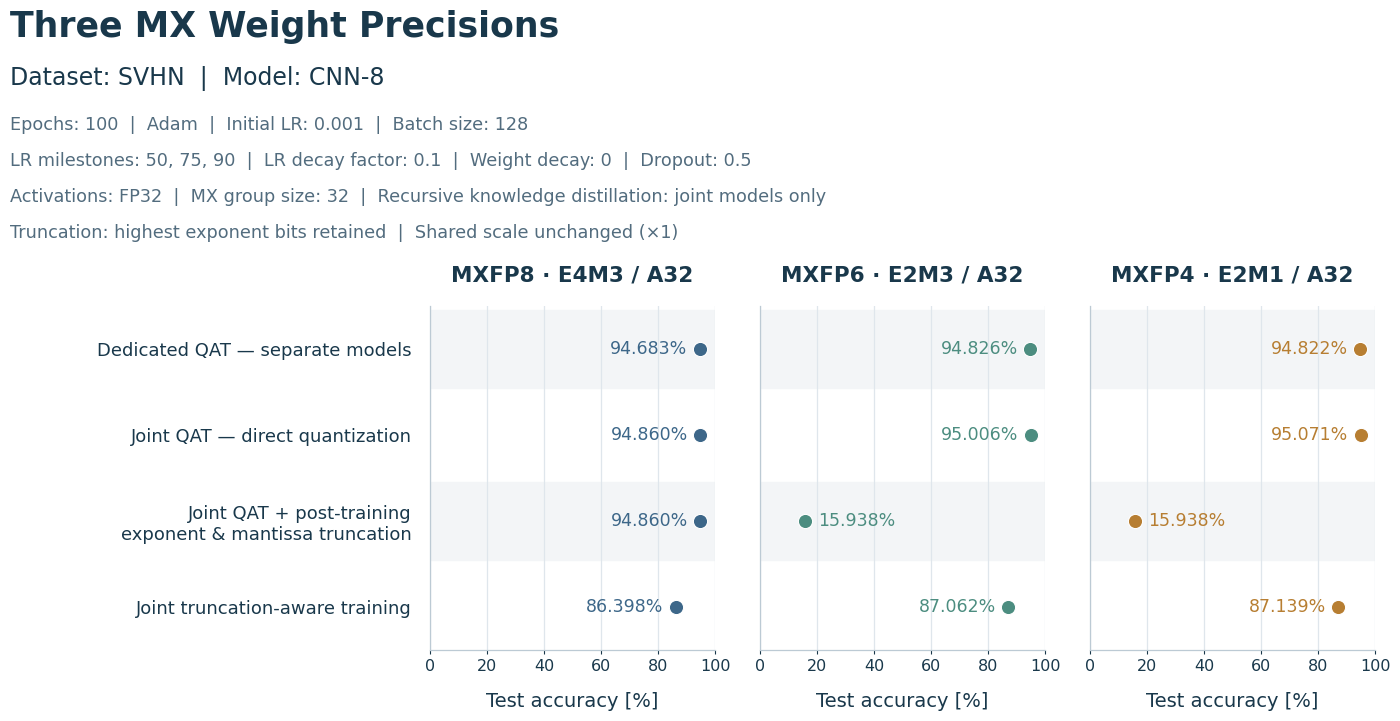

In [4]:
accuracy_rows = DATA['accuracy']
for row in accuracy_rows:
    for mode in DATA['formats']:
        value = row['values'][mode]
        assert value['epoch'] == 100 and value['n'] == 26032
        assert abs(100 * value['correct'] / value['n'] - value['accuracy_percent']) < 1e-6
        assert ACCURACY_XLIM[0] <= value['accuracy_percent'] <= ACCURACY_XLIM[1]
for value in accuracy_rows[2]['values'].values():
    assert value['optimizer_steps'] == 0 and not value['batchnorm_recalibrated']
    assert value['scale_exponent_offset'] == 0

method_labels = [
    'Dedicated QAT — separate models',
    'Joint QAT — direct quantization',
    'Joint QAT + post-training\nexponent & mantissa truncation',
    'Joint truncation-aware training',
]
fig_accuracy = plt.figure(figsize=FIGURE_SIZE)
add_heading(fig_accuracy, training=True)
accuracy_axes = []
for index, (mode, title, left) in enumerate([
    ('E4M3', 'MXFP8 · E4M3 / A32', 0.325),
    ('E2M3', 'MXFP6 · E2M3 / A32', 0.545),
    ('E2M1', 'MXFP4 · E2M1 / A32', 0.765),
]):
    ax = fig_accuracy.add_axes([left, 0.145, 0.190, 0.430])
    accuracy_axes.append(ax)
    style_axes(ax)
    for y in (0, 2):
        ax.axhspan(y - 0.45, y + 0.45, color=ROW_BAND, zorder=0)
    ax.xaxis.grid(True, color=GRID, linewidth=0.9)
    values = [row['values'][mode]['accuracy_percent'] for row in accuracy_rows]
    ax.scatter(values, list(range(4)), s=105, color=MODE_COLORS[mode],
               edgecolors='white', linewidths=0.8, zorder=3)
    for y, value in enumerate(values):
        on_right = value >= (ACCURACY_XLIM[0] + 0.7 * (ACCURACY_XLIM[1] - ACCURACY_XLIM[0]))
        ax.annotate(f'{value:.{LABEL_DECIMALS}f}%', (value, y),
                    xytext=(-9 if on_right else 9, 0), textcoords='offset points',
                    ha='right' if on_right else 'left', va='center',
                    fontsize=12.5, color=MODE_COLORS[mode])
    ax.set_xlim(*ACCURACY_XLIM)
    ax.set_ylim(3.5, -0.5)
    ax.xaxis.set_major_locator(FixedLocator(ACCURACY_XTICKS))
    ax.set_yticks(list(range(4)), method_labels if index == 0 else [''] * 4)
    ax.tick_params(axis='y', length=0, labelsize=13, pad=13)
    ax.tick_params(axis='x', labelsize=11.5)
    ax.set_title(title, fontsize=15.5, weight='bold', pad=18)
    ax.set_xlabel('Test accuracy [%]', fontsize=14, labelpad=13)
plt.show()


### Values shown

| Method | MXFP8 · E4M3 | MXFP6 · E2M3 | MXFP4 · E2M1 |
|:--|--:|--:|--:|
| Dedicated QAT — separate models | 94.683% | 94.826% | 94.822% |
| Joint QAT — direct quantization | 94.860% | 95.006% | 95.071% |
| Joint QAT + post-training exponent & mantissa truncation | 94.860% | 15.938% | 15.938% |
| Joint truncation-aware training | 86.398% | 87.062% | 87.139% |

The two post-training low modes predict class 2 for every test image. Their 15.938% accuracy is 4,149 correct predictions out of 26,032, the test-set fraction of that class. It should not be described as 10% random guessing. Training with the naive truncation route recovers substantial accuracy, but this experiment still remains well below the direct-QAT results. These results motivate the later shared-scale correction experiments; those are not mixed into this figure.


## 4. Which representation is stored?

**Dedicated models:** three independently trained models, one per weight format. The inference representation retains each model's packed weights, block scales and auxiliary model state.

**Joint QAT + post-training truncation:** one MXFP8 source. The MXFP6 and MXFP4 codes are derived using the third accuracy row's naive exponent/mantissa truncation route with unchanged scale. This representation supports all three modes, with the measured 15.938% accuracy for both lower modes.

**Joint truncation-aware training:** one MXFP8 source trained using that truncation route. The lower formats are derived from this source with the same scale rule. This is the fourth accuracy row, with original logged accuracies of 86.398%, 87.062% and 87.139%.

The middle storage bar corresponds to the **third accuracy row**, not the second row's direct quantization. Direct quantization of each format from FP32 master weights is a different inference route; saving only the high-precision MX representation and truncating it does not preserve the direct low-mode result in general.

All cases retain the FP32 first convolution and final classifier and their BatchNorm state. The FP32 master copies of the six MX-quantized weight tensors are not required for the compact inference representation. The existing training procedure does use FP32 masters and training state.

Activations are needed during inference and remain A32 in these experiments. They are generated for each input and belong to runtime working memory rather than persistent model storage. The current emulator also uses floating-point tensors for computation. Packed storage therefore does not by itself measure peak RAM/VRAM, native MX execution, or hardware energy savings.


## 5. Storage accounting

The metric is the **logical persistent model payload supporting all three modes**. It includes code padding, one 8-bit E8M0 scale per group, FP32 first/last layers and retained BatchNorm state. It excludes file-container overhead, activations, optimizer state, gradients, temporary decoded copies and convolution workspaces.

The six MX layers contain 129,472 weights. Group size 32 gives 4,080 blocks and 130,560 stored slots, including 1,088 padding slots. The packed codes occupy 130,560 bytes for MXFP8, 97,920 bytes for MXFP6 and 65,280 bytes for MXFP4. Each stored representation also has 4,080 scale bytes.

Each model copy retains 19,248 auxiliary bytes: 8,808 bytes for FP32 first/last layers and 10,440 bytes for **all five existing BatchNorm banks**, including counters. No unused-bank pruning is assumed. Dedicated models need three copies of their independently trained auxiliary state. Each joint model needs one copy, which already includes all target-mode BatchNorm banks.

The joint-direct high-format export's recorded logical payload matches the shape-derived MXFP8 layout. The truncation-aware source has the same layout. Their equal storage bars therefore describe equal representation sizes with different measured accuracies.


In [5]:
accounting = DATA['storage_accounting']
assert accounting['stored_slots'] == accounting['group_count'] * accounting['group_size']
assert accounting['stored_slots'] - accounting['target_weight_count'] == accounting['padding_slots']
for bits, key in [(8, 'mxfp8_code_bytes'), (6, 'mxfp6_code_bytes'), (4, 'mxfp4_code_bytes')]:
    assert accounting['stored_slots'] * bits // 8 == accounting[key]
assert accounting['fp32_first_last_bytes_per_model'] + accounting['batchnorm_bytes_per_model_all_five_banks'] == accounting['retained_state_bytes_per_model']

storage_rows = DATA['storage']
for row in storage_rows:
    assert row['code_bytes'] + row['scale_bytes'] + row['retained_state_bytes'] == row['total_bytes']
assert [row['total_bytes'] for row in storage_rows] == [363744, 153888, 153888]
assert [row['auxiliary_copies'] for row in storage_rows] == [3, 1, 1]
assert storage_rows[1]['accuracy_method_id'] == accuracy_rows[2]['id']
for row in storage_rows:
    print(f"{row['label']}: {row['total_bytes']:,} bytes = {row['total_bytes'] / 1024:.6f} KiB")


Dedicated models: 363,744 bytes = 355.218750 KiB
Joint QAT + post-training truncation: 153,888 bytes = 150.281250 KiB
Joint truncation-aware training: 153,888 bytes = 150.281250 KiB


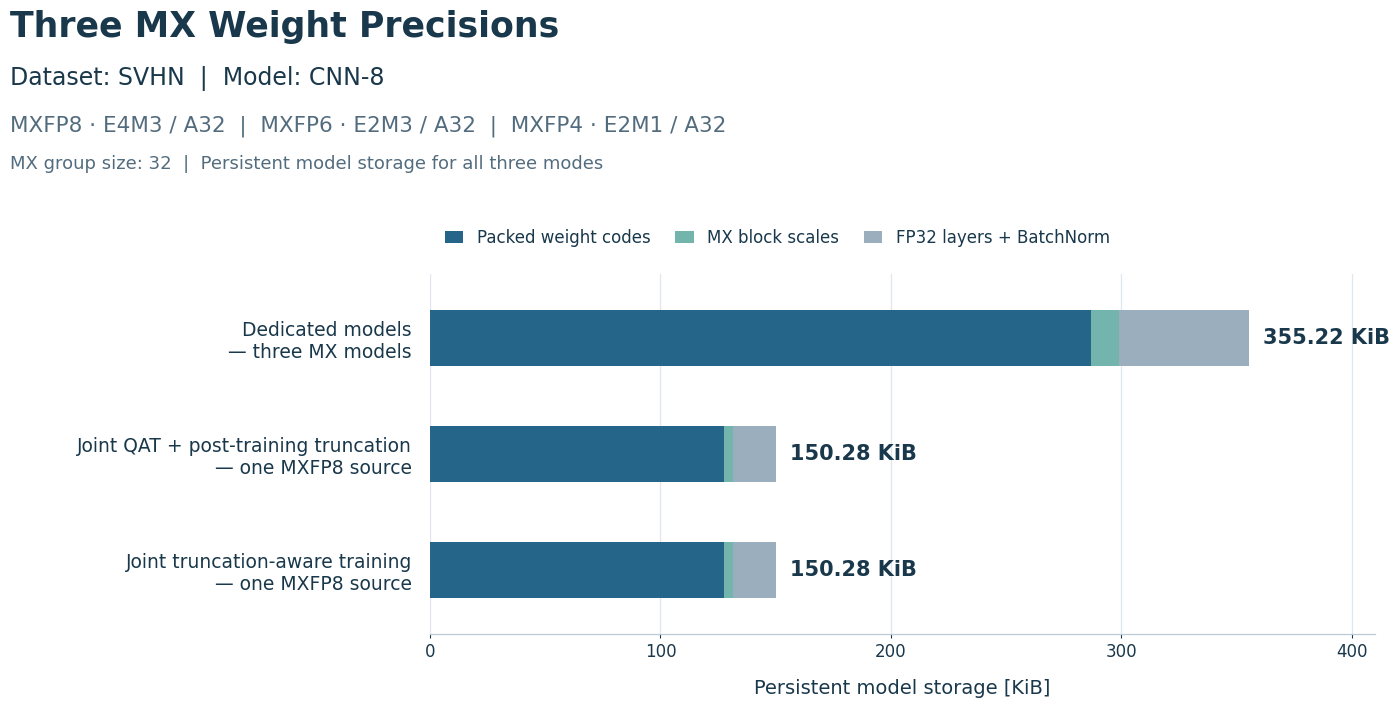

In [6]:
fig_storage = plt.figure(figsize=FIGURE_SIZE)
add_heading(fig_storage, training=False)
ax_storage = fig_storage.add_axes([0.325, 0.165, 0.630, 0.450])
style_axes(ax_storage)
ax_storage.spines['left'].set_visible(False)
ax_storage.xaxis.grid(True, color=GRID, linewidth=0.9)

component_fields = ['code_bytes', 'scale_bytes', 'retained_state_bytes']
component_labels = ['Packed weight codes', 'MX block scales', 'FP32 layers + BatchNorm']
storage_labels = [
    'Dedicated models\n— three MX models',
    'Joint QAT + post-training truncation\n— one MXFP8 source',
    'Joint truncation-aware training\n— one MXFP8 source',
]
for y, row in enumerate(storage_rows):
    left = 0.0
    for field, color in zip(component_fields, STORAGE_COLORS):
        width = row[field] / 1024
        ax_storage.barh(y, width, left=left, height=0.48, color=color, zorder=3)
        left += width
    ax_storage.annotate(f"{row['total_bytes'] / 1024:.2f} KiB", (left, y),
                        xytext=(10, 0), textcoords='offset points',
                        ha='left', va='center', fontsize=15, weight='bold')
ax_storage.set_yticks([0, 1, 2], storage_labels)
ax_storage.tick_params(axis='y', length=0, labelsize=13.5, pad=13)
ax_storage.set_ylim(2.55, -0.55)
ax_storage.set_xlim(0, 410)
ax_storage.set_xticks([0, 100, 200, 300, 400])
ax_storage.set_xlabel('Persistent model storage [KiB]', fontsize=14, labelpad=13)
fig_storage.legend(
    handles=[Patch(facecolor=color, label=label) for color, label in zip(STORAGE_COLORS, component_labels)],
    loc='upper left', bbox_to_anchor=(0.325, 0.690), ncol=3,
    frameon=False, fontsize=12, handlelength=1.1, columnspacing=1.5,
)
plt.show()


## 6. Export

PNG is exported at 300 dpi. SVG preserves vector shapes and editable text. Re-running this cell updates only the named outputs in `figures/`. CSV and JSON preserve the original unrounded metrics and integer byte counts.


In [7]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
for name, figure in [('mx_exponent_accuracy', fig_accuracy), ('mx_exponent_storage', fig_storage)]:
    for extension in ('png', 'svg'):
        buffer = io.BytesIO()
        figure.savefig(buffer, format=extension, dpi=EXPORT_DPI, facecolor='white')
        target = EXPORT_DIR / f'{name}.{extension}'
        target.write_bytes(buffer.getvalue())
        print(f'Saved: {target.as_posix()}')

flat_accuracy = [
    {'method_id': row['id'], 'method': row['label'], 'format': mode,
     'accuracy_percent': row['values'][mode]['accuracy_percent'],
     'correct': row['values'][mode]['correct'], 'n': row['values'][mode]['n']}
    for row in accuracy_rows for mode in DATA['formats']
]
for filename, rows in [('accuracy.csv', flat_accuracy), ('storage.csv', storage_rows)]:
    with (EXPORT_DIR / filename).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
(EXPORT_DIR / 'figure_data.json').write_text(json.dumps(DATA, indent=2) + '\n', encoding='utf-8')
print('Saved: accuracy.csv, storage.csv and figure_data.json')


Saved: figures/mx_exponent_accuracy.png
Saved: figures/mx_exponent_accuracy.svg
Saved: figures/mx_exponent_storage.png
Saved: figures/mx_exponent_storage.svg
Saved: accuracy.csv, storage.csv and figure_data.json


## 7. Provenance and limits

All measurements come from the audited embedded data in `MX_onderzoeksoverzicht_meeting_20261029.ipynb`. The five training IDs are `dedicated_e4m3`, `dedicated_mxfp6`, `dedicated_mxfp4`, `triple_direct` and `triple_naive`. Post-training measurements are the `direct8`, `exponent86` and `combined864` cases from `triple_initial`, evaluated on `triple_direct`'s final checkpoint. Source member names, configuration records, checkpoint hashes, metric hashes and per-image verification metadata are embedded in `DATA`.

The two post-training low modes were independently recounted as 4,149 correct images out of 26,032 and predict class 2 throughout. Their BatchNorm banks were not recalibrated. The comparison therefore reflects both the altered weight route and its interaction with the previously trained BatchNorm state.

Storage uses `triple_dedicated_separate`, `mx_e4m3_b32` and `triple_naive_source`, plus the recorded joint-direct MXFP8 export size. These are logical packed code/tensor payloads, not `.pt` file sizes. This notebook does not reload binary checkpoints or exports and does not rerun model inference. The post-training accuracy measurements are preserved from the original evaluation; no new source-only runtime equivalence test is claimed here.

Later ×32/×64 scale corrections, learned scales and other group sizes are deliberately outside this slide's comparison. Training used FP32 masters; inference storage and a resumable training checkpoint have different requirements.
